# Analytic Covariance Matrices (Linear LIMD)

Analytic covariances for the power spectrum, the P–B cross term, and the bispectrum, built from the linear LIMD
bias model ($b_1$, $b_2$, $b_3$, linear matter) with the bias values taken from the `Lin_b3` fits.
Copied from `Bispectrum/Covariance_Matrix/` (`Power_Covariance.ipynb`, `Cross_Covariance.ipynb`, `Bispec_Covariance.ipynb`).
Bias values are in the fitting convention (no factors of 2 or 6), matching the `b2b2`/`b3b3` templates used for $I$ and $I_3$.

## v1 vs v2

**v1** is purely analytic, no noise:
* Power spectrum diagonal: Gaussian $2b_1^4P^2/N_k$ plus the non-Gaussian $4b_1^2b_2^2PI/N_k$.
* Bispectrum Gaussian part: $V b_1^6 P_1P_2P_3\,s_{123}/N_{123}$, and the $b_1^4b_2^2$ "class 5" term ($V\,I\,P\,P/N_{123}$) is included.

**v2** puts a full model of the power spectrum, including shot noise, into the Gaussian parts:
* $P_\mathrm{tot}(k) = b_1^2P + b_2^2I + b_3^2I_3 + b_{PN}\bar n^{-1} + b_{Pk^2N}\bar n^{-1}k^2$
* Power spectrum diagonal: $2P_\mathrm{tot}^2/N_k$.
* Bispectrum Gaussian part: $V P_\mathrm{tot}(k_1)P_\mathrm{tot}(k_2)P_\mathrm{tot}(k_3)\,s_{123}/N_{123}$, and class 5 is dropped (its $b_2^2 I$ piece is now inside $P_\mathrm{tot}$).

The off-diagonal (connected) terms and the P–B cross covariance are the same in both versions and contain no noise.
Note: the original `Power_Cov_v2` noise had no $k^2$ piece; it is included here since the fits keep the $k^2$ noise on.

In [1]:
import sys
sys.path.append('/home/kboone/software/Galaxy_Bias/Bispectrum/Convert_Bispectrum/')

import os
import h5py
import numpy as np
import pandas as pd
import Visual_Helpers as VH
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.interpolate import interp1d as inter
from scipy.interpolate import CubicSpline as spline

import matplotlib
matplotlib.style.use('boone')

cmap = plt.get_cmap("tab10")

In [2]:
# Only change the variables in this block from run to run.
version = 'v1'  # 'v1' or 'v2'
assert version in ('v1', 'v2'), "version must be 'v1' or 'v2'"

fit_file = 'Fits_z8/Lin_b3_Best_Fits.npy'
pos_root = '../../Data/Gala_z8_Positions/'
data_dir = '/mnt/nvme1/kboone/Data/BigFiles/Gala_8/'
model_root = '/mnt/nvme1/kboone/Sims/'
shift_kmax = 1.0
write_root = 'Covariances/'
os.makedirs(write_root, exist_ok=True)

In [3]:
phases = 25
z = 8  # The linear power spectrum normalization below is for z = 8.
rescale = (8+1)/(z+1)

L = 2000
V = L**3
N_grid = 256
kF = 2*np.pi/L
kN = N_grid*np.pi/L

In [4]:
# Mean over phases of the Lin_b3 best fits. Order: bPN, bPk2N, bBCN, bBPN, b1, b2, bK2, bOtd, bk2, b3
fits = np.load(fit_file)
bP, bPk2, b1, b2, b3 = np.average(fits[:, [0, 1, 4, 5, 9]], axis=0)
print(f'b1 = {b1:.3f}, b2 = {b2:.3f}, b3 = {b3:.3f}, bPN = {bP:.3f}, bPk2N = {bPk2:.3f}')

b1 = 9.837, b2 = 42.308, b3 = 72.028, bPN = 1.064, bPk2N = 0.197


In [5]:
power_dir = '/home/kboone/software/Galaxy_Bias/Bispectrum/Two_Points_Data/'
model_power_file = power_dir + 'CLASS_power_z1' # Location of power spectrum file
k_model_orig, Pk_model_orig = VH.read_power(model_power_file)
max_k_model = np.max(k_model_orig)
Pk_model_orig = Pk_model_orig * (0.2322)**2 # Normalization to z=8

P = spline(k_model_orig, Pk_model_orig, bc_type='natural')

In [6]:
def get_P(directory = data_dir):
    phases = 25
    Pk = []
    for ph in np.arange(phases):
        power_file = directory + 'Gala_ph0' + '{:02d}'.format(ph) + '/Gala_256_ps.dat'
        
        df = pd.read_csv(power_file, sep=r'\s+')
        
        # Shift the header row to the left
        df.columns = np.roll(df.columns, -1)
        
        # Drop the first column (which now contains the original header)
        df = df.drop(df.columns[-1], axis=1)
        k = df['k_mean_over_bin_[h_Mpc^-1]'].to_numpy()
        N = df['N_modes'].to_numpy()
        Pk.append(df['P_bin_[h^-3_Mpc^3]'].to_numpy())
        
    Pk = np.array(Pk)
    return k, N, Pk


def get_sim_Pk(directory, abbreviation, symfactor=1):
    all_files = os.listdir(directory)
    files = np.array([file for file in all_files if 
                      file.endswith('.dat') and file.startswith(abbreviation) and '_v' in file])
    Pk = []
    for file in files:
        power_file = directory + file
        
        df = pd.read_csv(power_file, sep=r'\s+')
        
        # Shift the header row to the left
        df.columns = np.roll(df.columns, -1)
        
        # Drop the first column (which now contains the original header)
        df = df.drop(df.columns[-1], axis=1)
        k = df['k_mean_over_bin_[h_Mpc^-1]'].to_numpy()
        Pk.append(df['P_bin_[h^-3_Mpc^3]'].to_numpy())
        
    Pk = np.array(Pk)
    return Pk*symfactor


def data_bispec(bs_file, min_k, max_k, min_ksum, max_ksum):
    # This is for not doing any rounding, leads to ~10 times more points to compute
    # This is necessary in comparing to computed data though.
    df = pd.read_csv(bs_file, sep=r'\s+')
    
    # Shift the header row to the left
    df.columns = np.roll(df.columns, -1)
    
    # Drop the first column (which now contains the original header)
    df = df.drop(df.columns[-1], axis=1)
    
    B=np.array(df['B_bin_[h^-6_Mpc^6]'])
    N=np.array(df['N_modes'])
    k1=np.array(df['k1_mean_[h_Mpc^-1]'])
    k2=np.array(df['k2_mean_[h_Mpc^-1]'])
    k3=np.array(df['k3_mean_[h_Mpc^-1]'])
    
    ksum = k1+k2+k3
    cropInds = np.where((ksum >= min_ksum) & (ksum <= max_ksum) & 
                        (k1 >= min_k) & (k1 <= max_k) & 
                        (k2 >= min_k) & (k2 <= max_k) & 
                        (k3 >= min_k) & (k3 <= max_k))[0]

    B = B[cropInds]
    N = N[cropInds]
    k1 = k1[cropInds]
    k2 = k2[cropInds]
    k3 = k3[cropInds]
    ksum = ksum[cropInds]

    sortInds = np.argsort(ksum)
        
    B = B[sortInds]
    N = N[sortInds]
    k1 = k1[sortInds]
    k2 = k2[sortInds]
    k3 = k3[sortInds]
    
    ineqCrop = np.where((k1 >= k2) & (k2 >= k3))[0]
    
    B = B[ineqCrop]
    N = N[ineqCrop]
    k1 = k1[ineqCrop]
    k2 = k2[ineqCrop]
    k3 = k3[ineqCrop]
    
    BCrop = np.where(np.abs(B) < 1e12)[0] # Removes numerical issues
    
    B = B[BCrop]
    N = N[BCrop]
    k1 = k1[BCrop]
    k2 = k2[BCrop]
    k3 = k3[BCrop]

    return B, N, np.array([k1, k2, k3]).T

In [7]:
noises = np.zeros(phases, dtype=np.float64)

for ph in np.arange(phases):
    pos_file = pos_root + 'Gala_ph0' + '{:02d}'.format(ph) + '.h5'
    
    with h5py.File(pos_file, 'r') as f_:
        dset = f_['dataset']
        pos = dset[:].T
        noises[ph] = V/len(pos)

ave_noise = V / np.average(V / noises)

In [8]:
I_data = np.average(get_sim_Pk(model_root + 'PowerSpectra/', 'b2b2'), axis=0)
I3_data = np.average(get_sim_Pk(model_root + 'PowerSpectra/', 'b3b3'), axis=0)

# Power Spectrum Covariance

In [9]:
k, Nk, Pk = get_P(directory = data_dir)
std_P = np.std(Pk, axis=0, ddof=1)
std_cov = np.outer(std_P, std_P)
cov_P = np.cov(Pk.T, ddof=1)
kMax_P = kN

I = spline(k, I_data, bc_type='natural')
I3_spl = spline(k, I3_data, bc_type='natural')  # Not named I3, which is reused for an array below

def nonlin_P(k):
    return b1**2*P(k) + b2**2*I(k) + b3**2*I3_spl(k) + bP*np.average(noises) + bPk2*np.average(noises)*k**2

In [10]:
def A_P_integrand(mu, k, kp):
    return P(np.sqrt(k**2 + kp**2 + 2*k*kp*mu))


def A_P(k, kp):
    '''
    Angular average of the k and k' (I call kp) sum.
    '''
    return 0.5 * quad(A_P_integrand, -1, 1, args=(k,kp))[0]

In [11]:
if version == 'v1':
    diag_comp = 2*b1**4*P(k)**2/Nk + 4*b1**2*b2**2*P(k)*I(k)/Nk
else:
    diag_comp = 2*nonlin_P(k)**2/Nk

power_cov = np.diag(diag_comp)
for i in np.arange(len(k)):
    for j in np.arange(len(k)):
        if i < j:
            continue
        K = k[i]; KP = k[j]
        AKKP = A_P(K,KP)
        power_cov[i,j] += 8*b1**2*b2**2*(P(K)**2+P(KP)**2)/V * AKKP
        power_cov[i,j] += 16*b1**2*b2**2*P(K)*P(KP)/V * AKKP
        power_cov[i,j] += 12*b1**3*b3*P(K)*P(KP)*(P(K)+P(KP))/V
        if i > j:
            power_cov[j,i] += 8*b1**2*b2**2*(P(K)**2+P(KP)**2)/V * AKKP
            power_cov[j,i] += 16*b1**2*b2**2*P(K)*P(KP)/V * AKKP
            power_cov[j,i] += 12*b1**3*b3*P(K)*P(KP)*(P(K)+P(KP))/V

np.save(write_root + 'Power_Cov_' + version + '.npy', power_cov)

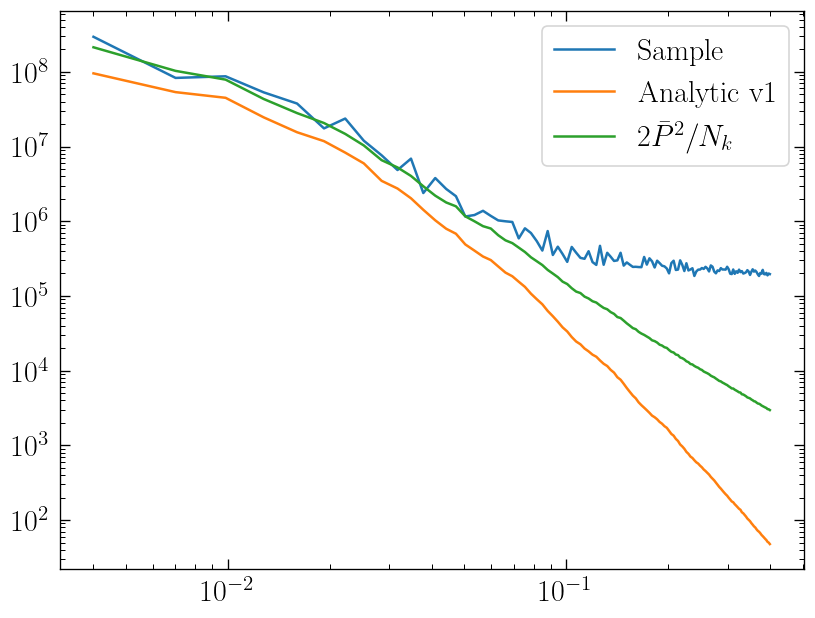

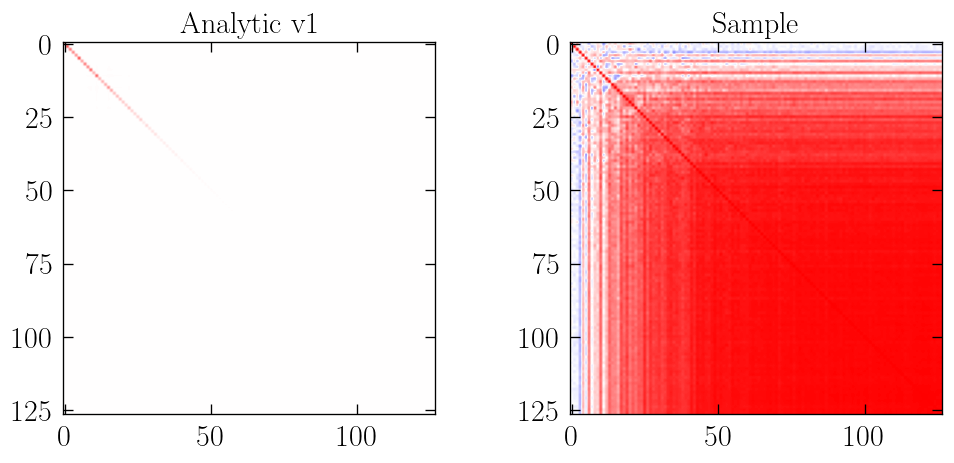

In [12]:
plt.figure(dpi = 120)
plt.loglog(k, np.diag(cov_P), label='Sample')
plt.loglog(k, np.diag(power_cov), label='Analytic ' + version)
plt.loglog(k, 2*np.average(Pk, axis=0)**2/Nk, label=r'$2\bar P^2/N_k$')
plt.legend()
plt.show()

fig, axs = plt.subplots(1, 2, dpi = 120, figsize=(10, 4))
axs[0].imshow(power_cov/std_cov, cmap='bwr', vmin=-1, vmax=1)
axs[0].set_title('Analytic ' + version)
axs[1].imshow(cov_P/std_cov, cmap='bwr', vmin=-1, vmax=1)
axs[1].set_title('Sample')
plt.show()

# Bispectrum Data and Binning

In [13]:
max_ksum = kN * shift_kmax
min_ksum = max_ksum/4

min_k = 0.5*kF * shift_kmax
max_k = 64.5*kF * shift_kmax
Bs = []

for ph in np.arange(phases):
    bs_file = data_dir + 'Gala_ph0' + '{:02d}'.format(ph) + '/Gala_256_comb.dat'
    B, N123, kB = data_bispec(bs_file, min_k, max_k, min_ksum, max_ksum)
    Bs.append(B)

Bs = np.array(Bs)
k1, k2, k3 = kB[:,0], kB[:,1], kB[:,2]

k_round = np.round((k/kF+0.5)/2).astype(int)
k1_round = np.round((k1/kF+0.5)/2).astype(int)
k2_round = np.round((k2/kF+0.5)/2).astype(int)
k3_round = np.round((k3/kF+0.5)/2).astype(int)

# Cross Covariance (same for v1 and v2)

In [14]:
k_over_Nk_k1 = ((k/Nk)[:, None] / k1[None, :])
k_over_Nk_k2 = ((k/Nk)[:, None] / k2[None, :])
k_over_Nk_k3 = ((k/Nk)[:, None] / k3[None, :])

deltakk1 = (k_round[:, None] == k1_round[None, :]).astype(int)
deltakk2 = (k_round[:, None] == k2_round[None, :]).astype(int)
deltakk3 = (k_round[:, None] == k3_round[None, :]).astype(int)

P_k = P(k)[:, None]
P_k1 = P(k1)[None, :]
P_k2 = P(k2)[None, :]
P_k3 = P(k3)[None, :]

In [15]:
# Factor of 2, comes from the 4 times a one half.
cross_cov = 2*b1**4*b2*(deltakk1 * k_over_Nk_k1 * (P_k*P_k2*P_k3 + P_k**2*(P_k2+P_k3)) + 
                        deltakk2 * k_over_Nk_k2 * (P_k*P_k1*P_k3 + P_k**2*(P_k1+P_k3)) +
                        deltakk3 * k_over_Nk_k3 * (P_k*P_k1*P_k2 + P_k**2*(P_k1+P_k2)))

dat_cross = np.cov(Pk.T, Bs.T)[:Pk.shape[1],Pk.shape[1]:]

np.save(write_root + 'Cross_Cov.npy', cross_cov)

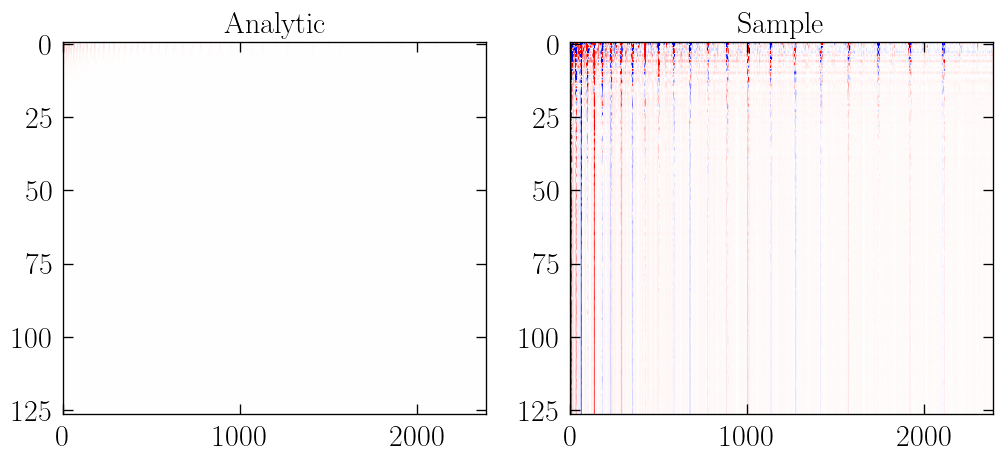

In [16]:
max_cross = np.max(np.abs(cross_cov))

fig, axs = plt.subplots(1, 2, dpi = 120, figsize=(10, 4))
axs[0].imshow(cross_cov/max_cross, aspect='auto', vmin=-1, vmax=1, cmap='bwr')
axs[0].set_title('Analytic')
axs[1].imshow(dat_cross/max_cross, aspect='auto', vmin=-1, vmax=1, cmap='bwr')
axs[1].set_title('Sample')
plt.show()

# Bispectrum Covariance

In [17]:
# Index by ki_round, this gives the number of power spectrum modes in that bin.
Nk_B = np.bincount(k_round, weights=Nk)

N1_B = Nk_B[k1_round]
N2_B = Nk_B[k2_round]
N3_B = Nk_B[k3_round]

P_k1 = P(k1)
P_k2 = P(k2)
P_k3 = P(k3)

In [18]:
delta_k1k1 = (k1_round[:, None] == k1_round[None, :]).astype(int)
delta_k1k2 = (k1_round[:, None] == k2_round[None, :]).astype(int)
delta_k1k3 = (k1_round[:, None] == k3_round[None, :]).astype(int)

delta_k2k1 = (k2_round[:, None] == k1_round[None, :]).astype(int)
delta_k2k2 = (k2_round[:, None] == k2_round[None, :]).astype(int)
delta_k2k3 = (k2_round[:, None] == k3_round[None, :]).astype(int)

delta_k3k1 = (k3_round[:, None] == k1_round[None, :]).astype(int)
delta_k3k2 = (k3_round[:, None] == k2_round[None, :]).astype(int)
delta_k3k3 = (k3_round[:, None] == k3_round[None, :]).astype(int)

# The same shape and 
delta_shape_s123 = (delta_k1k1 * delta_k2k2 * delta_k3k3 +
                    delta_k1k1 * delta_k2k3 * delta_k3k2 + 
                    delta_k1k2 * delta_k2k1 * delta_k3k3 + 
                    delta_k1k2 * delta_k2k3 * delta_k3k1 +
                    delta_k1k3 * delta_k2k2 * delta_k3k1 +
                    delta_k1k3 * delta_k2k1 * delta_k3k2)

In [19]:
if version == 'v1':
    gaus_comp = np.diag(b1**6 * V * P_k1 * P_k2 * P_k3 * np.diag(delta_shape_s123) / N123)
else:
    gaus_comp = np.diag(V * nonlin_P(k1) * nonlin_P(k2) * nonlin_P(k3) * np.diag(delta_shape_s123) / N123)

In [20]:
def Q(phi, k_sum, k_other, k_fixed, kp_sum, kp_other, kp_fixed):
    '''
    Argument to P when doing an angular average of P(k_sum + kp_sum) while holding k_fixed fixed between both.
    c and cp are cosines of the angles in between k_sum and k_fixed, s and sp the sines.
    '''
    c = (k_sum**2 + k_fixed**2 - k_other**2) / (2*k_sum*k_fixed)
    cp = (kp_sum**2 + kp_fixed**2 - kp_other**2) / (2*kp_sum*kp_fixed)
    
    s = np.sqrt(1-c**2)
    sp = np.sqrt(1-cp**2)

    # Due to rounding errors, this could feasibly be slightly smaller than 0
    return np.sqrt(np.abs(k_sum**2 + kp_sum**2 + 2*k_sum*kp_sum*(s*sp*np.cos(phi) - c*cp)))


def A_integrand(phi, k_sum, k_other, k_fixed, kp_sum, kp_other, kp_fixed):
    return P(Q(phi, k_sum, k_other, k_fixed, kp_sum, kp_other, kp_fixed))


def A(k_sum, k_other, k_fixed, kp_sum, kp_other, kp_fixed):
    '''
    Angular average of the k_sum and kp_sum, holding k_fixed fixed.
    The finite size means I'll actually be using two separate fixed k's.
    '''
    return quad(A_integrand, 0, 2*np.pi, args=(k_sum, k_other, k_fixed, kp_sum, kp_other, kp_fixed))[0] / (2*np.pi)

def _A_nodes(a, b, n_phi):
    '''
    Mean of P(sqrt(a + b cos(phi))) over n_phi Gauss-Chebyshev nodes in phi.
    Chunked over pairs to keep the (n_pair, n_phi) temporary from blowing up memory.
    '''
    cos_phi = np.cos((np.arange(n_phi) + 0.5) * np.pi / n_phi)

    out = np.empty(len(a))
    chunk = max(1, int(2e7 // n_phi))
    for i in range(0, len(a), chunk):
        sl = slice(i, i + chunk)
        out[sl] = P(np.sqrt(np.abs(a[sl, None] + b[sl, None]*cos_phi))).mean(axis=1)
    return out


def A_vec(k_sum, k_other, k_fixed, kp_sum, kp_other, kp_fixed,
          n_phi=256, n_phi_deg=1 << 15, deg_thresh=1e-3):
    '''
    Vectorized A(). All arguments are arrays over pairs of triangles.

    Q**2 = a + b cos(phi), so the average over phi is a plain midpoint sum, which is
    Gauss-Chebyshev quadrature in cos(phi) and converges spectrally -- no adaptive
    integration needed. The exception: a >= b always (a - b = |k_sum + kp_sum|**2 at
    phi = pi), and when a ~ b the two triangles nearly anti-align, Q -> 0 at phi = pi,
    and P ~ k**ns puts a branch point right at the endpoint. Convergence there drops to
    O(n**-2), so those few pairs get many more nodes.
    '''
    c = (k_sum**2 + k_fixed**2 - k_other**2) / (2*k_sum*k_fixed)
    cp = (kp_sum**2 + kp_fixed**2 - kp_other**2) / (2*kp_sum*kp_fixed)

    s = np.sqrt(np.abs(1 - c**2))
    sp = np.sqrt(np.abs(1 - cp**2))

    a = k_sum**2 + kp_sum**2 - 2*k_sum*kp_sum*c*cp
    b = 2*k_sum*kp_sum*s*sp

    out = _A_nodes(a, b, n_phi)

    deg = np.where((a - b) < deg_thresh*a)[0]
    if len(deg):
        out[deg] = _A_nodes(a[deg], b[deg], n_phi_deg)
    return out

# Checks for Next Time

Looks like A_11 fixing 3=3' doesn't equal A_22 fixing 3=3'. ChatGPT said these were equal and all of my terms thus far have assumed they were equal. So go back and check for bugs here and ask ChatGPT for a check on its work to see if there are any mistakes there.

In [21]:
k_11_inds, kp_11_inds = np.where(delta_k1k1 == 1)
k_12_inds, kp_12_inds = np.where(delta_k1k2 == 1)
k_13_inds, kp_13_inds = np.where(delta_k1k3 == 1)

k_22_inds, kp_22_inds = np.where(delta_k2k2 == 1)
k_23_inds, kp_23_inds = np.where(delta_k2k3 == 1)

k_33_inds, kp_33_inds = np.where(delta_k3k3 == 1)


A_22_11_inds = np.average(np.array([A_vec(k2[k_11_inds], k3[k_11_inds], k1[k_11_inds], 
                                          k2[kp_11_inds], k3[kp_11_inds], k1[kp_11_inds]), 
                                    A_vec(k3[k_11_inds], k2[k_11_inds], k1[k_11_inds], 
                                          k3[kp_11_inds], k2[kp_11_inds], k1[kp_11_inds])]), axis=0)
A_23_11_inds = np.average(np.array([A_vec(k2[k_11_inds], k3[k_11_inds], k1[k_11_inds], 
                                          k3[kp_11_inds], k2[kp_11_inds], k1[kp_11_inds]), 
                                    A_vec(k3[k_11_inds], k2[k_11_inds], k1[k_11_inds], 
                                          k2[kp_11_inds], k3[kp_11_inds], k1[kp_11_inds])]), axis=0)


A_21_12_inds = np.average(np.array([A_vec(k2[k_12_inds], k3[k_12_inds], k1[k_12_inds], 
                                          k1[kp_12_inds], k3[kp_12_inds], k2[kp_12_inds]), 
                                    A_vec(k3[k_12_inds], k2[k_12_inds], k1[k_12_inds], 
                                          k3[kp_12_inds], k1[kp_12_inds], k2[kp_12_inds])]), axis=0)
A_23_12_inds = np.average(np.array([A_vec(k2[k_12_inds], k3[k_12_inds], k1[k_12_inds], 
                                          k3[kp_12_inds], k1[kp_12_inds], k2[kp_12_inds]), 
                                    A_vec(k3[k_12_inds], k2[k_12_inds], k1[k_12_inds], 
                                          k1[kp_12_inds], k3[kp_12_inds], k2[kp_12_inds])]), axis=0)


A_21_13_inds = np.average(np.array([A_vec(k2[k_13_inds], k3[k_13_inds], k1[k_13_inds], 
                                          k1[kp_13_inds], k2[kp_13_inds], k3[kp_13_inds]), 
                                    A_vec(k3[k_13_inds], k2[k_13_inds], k1[k_13_inds], 
                                          k2[kp_13_inds], k1[kp_13_inds], k3[kp_13_inds])]), axis=0)
A_22_13_inds = np.average(np.array([A_vec(k2[k_13_inds], k3[k_13_inds], k1[k_13_inds], 
                                          k2[kp_13_inds], k1[kp_13_inds], k3[kp_13_inds]), 
                                    A_vec(k3[k_13_inds], k2[k_13_inds], k1[k_13_inds], 
                                          k1[kp_13_inds], k2[kp_13_inds], k3[kp_13_inds])]), axis=0)


A_11_22_inds = np.average(np.array([A_vec(k1[k_22_inds], k3[k_22_inds], k2[k_22_inds], 
                                          k1[kp_22_inds], k3[kp_22_inds], k2[kp_22_inds]), 
                                    A_vec(k3[k_22_inds], k1[k_22_inds], k2[k_22_inds], 
                                          k3[kp_22_inds], k1[kp_22_inds], k2[kp_22_inds])]), axis=0)
A_13_22_inds = np.average(np.array([A_vec(k1[k_22_inds], k3[k_22_inds], k2[k_22_inds], 
                                          k3[kp_22_inds], k1[kp_22_inds], k2[kp_22_inds]), 
                                    A_vec(k3[k_22_inds], k1[k_22_inds], k2[k_22_inds], 
                                          k1[kp_22_inds], k3[kp_22_inds], k2[kp_22_inds])]), axis=0)


A_11_23_inds = np.average(np.array([A_vec(k1[k_23_inds], k3[k_23_inds], k2[k_23_inds], 
                                          k1[kp_23_inds], k2[kp_23_inds], k3[kp_23_inds]), 
                                    A_vec(k3[k_23_inds], k1[k_23_inds], k2[k_23_inds], 
                                          k2[kp_23_inds], k1[kp_23_inds], k3[kp_23_inds])]), axis=0)
A_12_23_inds = np.average(np.array([A_vec(k1[k_23_inds], k3[k_23_inds], k2[k_23_inds], 
                                          k2[kp_23_inds], k1[kp_23_inds], k3[kp_23_inds]), 
                                    A_vec(k3[k_23_inds], k1[k_23_inds], k2[k_23_inds], 
                                          k1[kp_23_inds], k2[kp_23_inds], k3[kp_23_inds])]), axis=0)


A_11_33_inds = np.average(np.array([A_vec(k1[k_33_inds], k2[k_33_inds], k3[k_33_inds], 
                                          k1[kp_33_inds], k2[kp_33_inds], k3[kp_33_inds]), 
                                    A_vec(k2[k_33_inds], k1[k_33_inds], k3[k_33_inds], 
                                          k2[kp_33_inds], k1[kp_33_inds], k3[kp_33_inds])]), axis=0)
A_12_33_inds = np.average(np.array([A_vec(k1[k_33_inds], k2[k_33_inds], k3[k_33_inds], 
                                          k2[kp_33_inds], k1[kp_33_inds], k3[kp_33_inds]), 
                                    A_vec(k2[k_33_inds], k1[k_33_inds], k3[k_33_inds], 
                                          k1[kp_33_inds], k2[kp_33_inds], k3[kp_33_inds])]), axis=0)


A_22_11 = np.zeros((len(k1), len(k1)))
A_22_11[k_11_inds, kp_11_inds] = A_22_11_inds

A_23_11 = np.zeros((len(k1), len(k1)))
A_23_11[k_11_inds, kp_11_inds] = A_23_11_inds


A_21_12 = np.zeros((len(k1), len(k1)))
A_21_12[k_12_inds, kp_12_inds] = A_21_12_inds

A_23_12 = np.zeros((len(k1), len(k1)))
A_23_12[k_12_inds, kp_12_inds] = A_23_12_inds


A_21_13 = np.zeros((len(k1), len(k1)))
A_21_13[k_13_inds, kp_13_inds] = A_21_13_inds

A_22_13 = np.zeros((len(k1), len(k1)))
A_22_13[k_13_inds, kp_13_inds] = A_22_13_inds


A_11_22 = np.zeros((len(k1), len(k1)))
A_11_22[k_22_inds, kp_22_inds] = A_11_22_inds

A_13_22 = np.zeros((len(k1), len(k1)))
A_13_22[k_22_inds, kp_22_inds] = A_13_22_inds


A_11_23 = np.zeros((len(k1), len(k1)))
A_11_23[k_23_inds, kp_23_inds] = A_11_23_inds

A_12_23 = np.zeros((len(k1), len(k1)))
A_12_23[k_23_inds, kp_23_inds] = A_12_23_inds


A_11_33 = np.zeros((len(k1), len(k1)))
A_11_33[k_33_inds, kp_33_inds] = A_11_33_inds

A_12_33 = np.zeros((len(k1), len(k1)))
A_12_33[k_33_inds, kp_33_inds] = A_12_33_inds

## $b_1^4 b_2^2$ Components

### First off, two classes where both $\delta^2$ are on the same bispectrum.

In [22]:
P1 = P_k1[:, None]
P2 = P_k2[:, None]
P3 = P_k3[:, None]

P1p = P_k1[None, :]
P2p = P_k2[None, :]
P3p = P_k3[None, :]

N1 = N1_B[:, None]
N2 = N2_B[:, None]
N3 = N3_B[:, None]

I1 = I(k1)[:, None]
I2 = I(k2)[:, None]
I3 = I(k3)[:, None]

In [23]:
same_class_3 = (P1p*P2p*P3p)/N3*(A_11_33+A_12_33+A_11_23.T+A_12_23.T+A_21_13.T+A_22_13.T)
same_class_3 += (P1p*P2p*P3p)/N2*(A_11_22+A_13_22+A_11_23+A_12_23+A_23_12.T+A_21_12.T)
same_class_3 += (P1p*P2p*P3p)/N1*(A_22_11+A_23_11+A_21_12+A_23_12+A_21_13+A_22_13)
same_class_3 *= 4*b1**4*b2**2
same_class_3 += same_class_3.T # Switch primed and unprimed

same_class_4 = (P1p*P2p*P3p)*(P3/N1)*(delta_k1k1+delta_k1k2+delta_k1k3)
same_class_4 += (P1p*P2p*P3p)*(P3/N2)*(delta_k2k1+delta_k2k2+delta_k2k3)
same_class_4 += (P1p*P2p*P3p)*(P2/N1)*(delta_k1k1+delta_k1k2+delta_k1k3)
same_class_4 += (P1p*P2p*P3p)*(P2/N3)*(delta_k3k1+delta_k3k2+delta_k3k3)
same_class_4 += (P1p*P2p*P3p)*(P1/N3)*(delta_k3k1+delta_k3k2+delta_k3k3)
same_class_4 += (P1p*P2p*P3p)*(P1/N2)*(delta_k2k1+delta_k2k2+delta_k2k3)
same_class_4 *= 4*b1**4*b2**2
same_class_4 += same_class_4.T # Switch primed and unprimed

same = same_class_3+same_class_4

In [24]:
same = same_class_3+same_class_4

### Next, five classes where the $\delta^2$ are on different bispectra.

In [25]:
other_class_2 = P2*P2p*P3*P3p*((delta_k2k2+delta_k2k3)/N2 + (delta_k3k2+delta_k3k3)/N3)
other_class_2 += P1*P2p*P3*P3p*((delta_k1k2+delta_k1k3)/N1 + (delta_k3k2+delta_k3k3)/N3)
other_class_2 += P2*P2p*P1*P3p*((delta_k2k2+delta_k2k3)/N2 + (delta_k1k2+delta_k1k3)/N1)

other_class_2 += P2*P1p*P3*P3p*((delta_k2k1+delta_k2k3)/N2 + (delta_k3k1+delta_k3k3)/N3)
other_class_2 += P1*P1p*P3*P3p*((delta_k1k1+delta_k1k3)/N1 + (delta_k3k1+delta_k3k3)/N3)
other_class_2 += P2*P1p*P1*P3p*((delta_k2k1+delta_k2k3)/N2 + (delta_k1k1+delta_k1k3)/N1)

other_class_2 += P2*P2p*P3*P1p*((delta_k2k2+delta_k2k1)/N2 + (delta_k3k2+delta_k3k1)/N3)
other_class_2 += P1*P2p*P3*P1p*((delta_k1k2+delta_k1k1)/N1 + (delta_k3k2+delta_k3k1)/N3)
other_class_2 += P2*P2p*P1*P1p*((delta_k2k2+delta_k2k1)/N2 + (delta_k1k2+delta_k1k1)/N1)

other_class_2 *= 4*b1**4*b2**2
# Class 4 is the same thing, this just ensures symmetry.
other_class_2_and_4 = (other_class_2 + other_class_2.T)

In [26]:
other_class_3 = (P2*P2p*P3p/N3)*(A_12_33+A_12_23.T) + (P2p*P3*P3p/N2)*(A_12_23+A_13_22)
other_class_3 += (P1*P2p*P3p/N3)*(A_11_33+A_11_23.T) + (P2p*P3*P3p/N1)*(A_22_13+A_23_12)
other_class_3 += (P2*P2p*P3p/N1)*(A_21_13+A_21_12) + (P2p*P1*P3p/N2)*(A_11_23+A_11_22)

other_class_3 += (P2*P2p*P1p/N3)*(A_21_13.T+A_11_23.T) + (P2p*P3*P1p/N2)*(A_21_12.T+A_11_22)
other_class_3 += (P1*P2p*P1p/N3)*(A_22_13.T+A_12_23.T) + (P2p*P3*P1p/N1)*(A_22_11+A_21_12)
other_class_3 += (P2*P2p*P1p/N1)*(A_23_11+A_23_12) + (P2p*P1*P1p/N2)*(A_23_12.T+A_13_22)

other_class_3 += (P2*P1p*P3p/N3)*(A_11_33+A_22_13.T) + (P1p*P3*P3p/N2)*(A_11_23+A_23_12.T)
other_class_3 += (P1*P1p*P3p/N3)*(A_12_33+A_21_13.T) + (P1p*P3*P3p/N1)*(A_21_13+A_23_11)
other_class_3 += (P2*P1p*P3p/N1)*(A_22_13+A_22_11) + (P1p*P1*P3p/N2)*(A_12_23+A_21_12.T)

other_class_3 *= 4*b1**4*b2**2

other_class_3 = (other_class_3 + other_class_3.T) / 2

In [27]:
other_class_5 = V*I1*P2*P3*delta_k1k1*(delta_k2k2*delta_k3k3 + delta_k2k3*delta_k3k2)/N123
other_class_5 += V*I2*P1*P3*delta_k2k1*(delta_k1k2*delta_k3k3 + delta_k1k3*delta_k3k2)/N123
other_class_5 += V*I3*P2*P1*delta_k3k1*(delta_k2k2*delta_k1k3 + delta_k2k3*delta_k1k2)/N123

other_class_5 += V*I1*P2*P3*delta_k1k2*(delta_k2k1*delta_k3k3 + delta_k2k3*delta_k3k1)/N123
other_class_5 += V*I2*P1*P3*delta_k2k2*(delta_k1k1*delta_k3k3 + delta_k1k3*delta_k3k1)/N123
other_class_5 += V*I3*P2*P1*delta_k3k2*(delta_k2k1*delta_k1k3 + delta_k2k3*delta_k1k1)/N123

other_class_5 += V*I1*P2*P3*delta_k1k3*(delta_k2k2*delta_k3k1 + delta_k2k1*delta_k3k2)/N123
other_class_5 += V*I2*P1*P3*delta_k2k3*(delta_k1k2*delta_k3k1 + delta_k1k1*delta_k3k2)/N123
other_class_5 += V*I3*P2*P1*delta_k3k3*(delta_k2k2*delta_k1k1 + delta_k2k1*delta_k1k2)/N123

other_class_5 *= b1**4*b2**2

other_class_5 = (other_class_5 + other_class_5.T) / 2

In [28]:
other_class_6 = P2*P3*P2p*P3p*delta_k1k1/N1
other_class_6 += P1*P3*P2p*P3p*delta_k2k1/N2
other_class_6 += P2*P1*P2p*P3p*delta_k3k1/N3

other_class_6 += P2*P3*P1p*P3p*delta_k1k2/N1
other_class_6 += P1*P3*P1p*P3p*delta_k2k2/N2
other_class_6 += P2*P1*P1p*P3p*delta_k3k2/N3

other_class_6 += P2*P3*P2p*P1p*delta_k1k3/N1
other_class_6 += P1*P3*P2p*P1p*delta_k2k3/N2
other_class_6 += P2*P1*P2p*P1p*delta_k3k3/N3

other_class_6 *= 4*b1**4*b2**2

other_class_6 = (other_class_6 + other_class_6.T) / 2

In [29]:
if version == 'v2':
    other_class_5 = 0 # Its b2^2 I piece is already in the v2 Gaussian part through nonlin_P.
other = other_class_2_and_4 + other_class_3 + other_class_5 + other_class_6

## $\delta^3$ Case

Only one case here.

In [30]:
d3 = P1p*P2p*P3p*(P2/N3*(delta_k3k1+delta_k3k2+delta_k3k3) + P3/N2*(delta_k2k1+delta_k2k2+delta_k2k3))
d3 += P1p*P2p*P3p*(P1/N3*(delta_k3k1+delta_k3k2+delta_k3k3) + P3/N1*(delta_k1k1+delta_k1k2+delta_k1k3))
d3 += P1p*P2p*P3p*(P2/N1*(delta_k1k1+delta_k1k2+delta_k1k3) + P1/N2*(delta_k2k1+delta_k2k2+delta_k2k3))
d3 *= 6*b1**5*b3
d3 += d3.T # Switch primed and unprimed

In [31]:
whole = gaus_comp + same + other + d3
np.save(write_root + 'Bispec_Cov_' + version + '.npy', whole)
np.save(write_root + 'Bispec_Cov_k.npy', kB)  # Triangles (k1, k2, k3) the bispectrum covariance is for

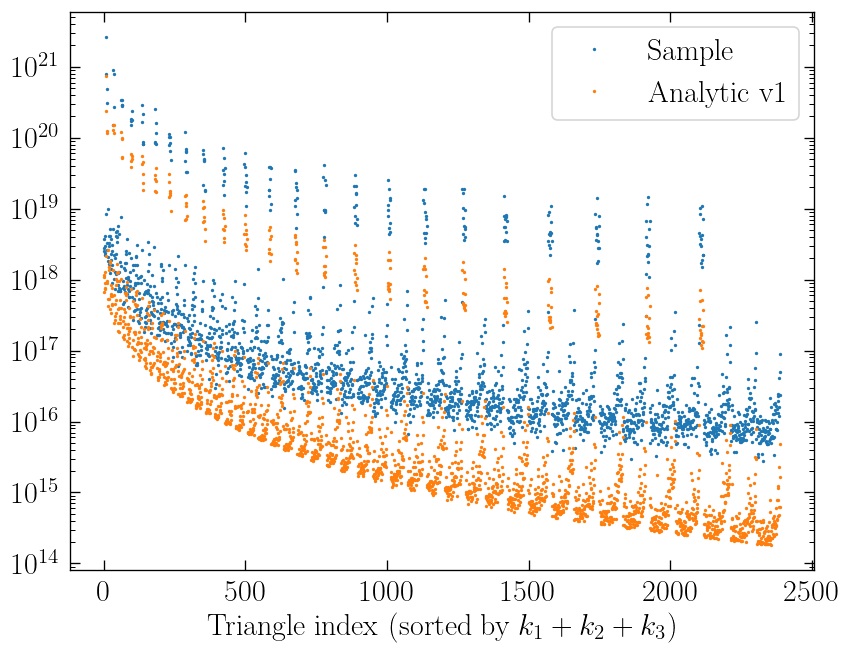

In [32]:
std_B = np.std(Bs, axis=0, ddof=1)

plt.figure(dpi = 120)
plt.semilogy(std_B**2, '.', ms=2, label='Sample')
plt.semilogy(np.diag(whole), '.', ms=2, label='Analytic ' + version)
plt.xlabel('Triangle index (sorted by $k_1+k_2+k_3$)')
plt.legend()
plt.show()